# 실험 2 — 2. AutoGluon: 모델 5종 베이지안 탐색(Optuna) + 가중 앙상블

`1_데이터준비.ipynb` 가 만든 `data/exp2/tabular.parquet`(600,075행 × 364피처 — 2026-10-01: 검사기관 코드 제거, 식품 값 표기 3칼럼 추가)로 AutoGluon(`autogluon.tabular` 1.6.3, Python 3.12 가상환경 `.venv-exp2`)을 돌린다. 결과는 MLflow 실험 `리스테리아_EXP2` 에 기록한다.

| 단계 | 내용 | 시간 |
|---|---|---|
| **탐색** | 모델 5가족(LightGBM·CatBoost·XGBoost·RandomForest·ExtraTrees)을 각각 **Optuna(TPE, 베이지안 최적화)** 로 최적화. Optuna 가 설정을 제안하면 AutoGluon 에 그 설정의 모델 하나를 학습시키고(`fit_extra`), val 의 `average_precision` 을 돌려준다. 가족마다 시간 예산 `BUDGET_H` 안에서 최대 `MAX_TRIALS` 회. 0회차로 각 가족의 라이브러리 기본 설정을 먼저 학습한다. 마지막에 전체 모델의 **가중 앙상블** | 기본 45분 + 예산 합 6h + 앙상블 15분 (약 7시간) |

> **배깅·스태킹은 하지 않는다**(2026-09-29 사용자 결정). 스태킹은 train 을 fold 로 나눠 out-of-fold 예측을 만들어야 하는데, 시간 순서를 지키는 분할이 아니라(뒤 시기로 앞 시기를 예측하는 fold 가 생김) 뺐다. 가중 앙상블은 val(train 뒤 1년)로 가중치를 정하므로 시간 순서가 지켜진다.

> **왜 AutoGluon 내장 탐색이 아니라 Optuna 인가** — AutoGluon 의 내장 탐색(`hyperparameter_tune_kwargs`)과 병렬 fold 학습은 Ray 위에서 도는데, 이 PC(Windows)에서는 `ray.init()` 이 보조 프로세스(raylet·GCS) 시작 시간 초과로 실패한다(2026-09-29 점검, 원인은 미확정 — 보안 프로그램·방화벽이 흔한 원인). Ray 가 되더라도 내장 탐색은 트리 모델에 무작위 탐색만 쓰고 RandomForest·ExtraTrees 는 아예 탐색하지 않으므로, Optuna 가 설정을 제안하고 AutoGluon 이 학습·채점하는 지금 방식이 더 낫다. 탐색 범위는 논문 범위에 묶지 않고 넓게 잡았다.

**공통 규칙 (실험 1과 같음)**
- 분할: train ~2024-06-30 · val 2024-07-01~2025-06-30 · test 2025-07-01~2026-06-30. test 는 마지막 평가에만 쓴다.
- val 의 쓰임: 조기 종료·탐색 채점·앙상블 가중치·임계값 선택(정석). 최종 성능은 test.
- 임계값 규칙 3개: 0.5 / val F1최대 / val F2최대. 지표: accuracy, precision, recall, f1, f2, roc_auc, pr_auc, 혼동행렬, 전체 건수(모든 비율은 0~1 소수).
- 불균형 처리: 재표집·클래스 가중은 탐색 대상에 넣지 않는다(성능향상_방안 §5-1; RF·XT 의 `class_weight` 만 탐색 선택지). 평가 지표를 `average_precision` 으로 두고 임계값을 옮긴다.
- 장치: **CatBoost·XGBoost 는 GPU**(XGBoost 는 GPU 지원 빌드로 교체), LightGBM·RF·XT 는 CPU. GPU 학습은 같은 seed 로 다시 돌려도 결과가 조금 달라질 수 있다.

> **`SMOKE_TEST = True`** 면 작은 표본·짧은 시간으로 파이프라인만 점검하고 MLflow 에 기록하지 않는다. 본 실행은 `False`.

## 1. 설정

In [1]:
import gc
import psutil
import json
import logging
import os
import sys
import tempfile
import time
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import sklearn
import optuna
import xgboost
import autogluon.tabular as agt
from autogluon.tabular import TabularPredictor
os.environ.setdefault('MLFLOW_DISABLE_AGENT_HINT', '1')
import mlflow
from dotenv import dotenv_values
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             roc_auc_score, average_precision_score, confusion_matrix, precision_recall_curve)

SMOKE_TEST = False      # True: 작은 표본·짧은 시간으로 점검만 (MLflow 기록 안 함)
LOG_TO_MLFLOW = True
SEED = 42
RUN_NAME = '2_autogluon'
RUN_STAMP = datetime.now().strftime('%Y%m%d_%H%M')

# A단계 시간 — 본 실행 값
T0_MIN = 45                                   # 0회차: 가족별 기본 설정 5개
BUDGET_H = {'GBM': 1.5, 'CAT': 1.0, 'XGB': 1.5, 'RF': 1.0, 'XT': 1.0}   # 가족별 Optuna 탐색 시간(시간)
MAX_TRIALS = 80                               # 가족별 최대 시도 수 (예산이 먼저 끝나면 그 전에 멈춤)
TRIAL_TIME_LIMIT_MIN = 20                     # 시도 하나(모델 하나)의 학습 시간 상한(분)
TW_MIN = 15                                   # 가중 앙상블
N_CPUS = 16
MEM_LIMIT_GB = 14                             # AutoGluon 이 가정하는 사용 가능 메모리(GB). AutoGluon 은 '이 값 − 노트북 프로세스 사용량'을 가용으로 본다.
# 8 로 했던 두 번째 시도(2026-09-29 19:10)에서 RF·XT 학습 뒤 프로세스 사용량이 약 7.3GB 로 올라 가용 0.73GB 로 계산 →
# XGBoost 기본 모델이 AutoGluon 메모리 점검에서 0 나누기 오류, LightGBM 탐색 시도가 '메모리 부족'으로 건너뛰어짐.
# 이 PC 는 RAM 15.9GB, 다른 프로그램을 빼면 약 9.6GB 여유 + 페이지 파일 21GB. 데이터 적재만으로 약 2.9GB 사용.
# AutoGluon 학습 전 메모리 검사 완화 배율 (ag.max_memory_usage_ratio, 기본 1.0).
# 본 실행 첫 시도(2026-09-29 18:34)에서 RF·XT 기본 모델이 '메모리 부족 예상'으로 건너뛰어짐(예상 4.3GB > 허용 약 3GB = 가용의 50%)
# → RF·XT 는 3.0(트리 600개 설정까지 통과; 학습 중에는 AutoGluon 이 실제 트리 크기를 재서 트리 수를 줄이는 안전장치가 따로 있음),
#   CatBoost 는 깊은 설정 일부가 건너뛰어져(예상 6.1GB > 가용 5.2GB) 1.5, 나머지 1.5.
MEM_RATIO = {'GBM': 1.5, 'CAT': 1.5, 'XGB': 1.5, 'RF': 3.0, 'XT': 3.0}

PROJECT_DIR = Path(r'C:\Users\NT751\Desktop\천영진\리스테리아ML')
DATA_DIR = PROJECT_DIR / 'data' / 'exp2'
AG_OUT = PROJECT_DIR / 'output' / 'exp2' / 'autogluon' / (('smoke_' if SMOKE_TEST else '') + RUN_STAMP)   # 모델 저장 (git 제외)
OPTUNA_DIR = PROJECT_DIR / (dotenv_values(PROJECT_DIR / '.env').get('AFLA_OPTUNA_DIR') or 'output')
OPTUNA_DIR.mkdir(parents=True, exist_ok=True)
OPTUNA_STORAGE = 'sqlite:///' + (OPTUNA_DIR / ('optuna_exp2_ag_smoke.db' if SMOKE_TEST else 'optuna_exp2_ag.db')).as_posix()
if SMOKE_TEST:
    T0_MIN, TW_MIN, TRIAL_TIME_LIMIT_MIN, MAX_TRIALS = 4, 1, 2, 2
    BUDGET_H = {k: 0.04 for k in BUDGET_H}     # 가족당 약 2.4분
    LOG_TO_MLFLOW = False
KEY_COL, DATE_COL = 'lims_data_key', 'mnfctur_de'
XGB_GPU = bool(xgboost.build_info().get('USE_CUDA'))

MLFLOW_URI = dotenv_values(PROJECT_DIR / '.env').get('AFLA_MLFLOW_URI')
assert MLFLOW_URI, '.env 에 AFLA_MLFLOW_URI 가 없음'
if MLFLOW_URI.startswith('sqlite:///') and not Path(MLFLOW_URI.removeprefix('sqlite:///')).is_absolute():
    MLFLOW_URI = 'sqlite:///' + (PROJECT_DIR / MLFLOW_URI.removeprefix('sqlite:///')).as_posix()
MLFLOW_EXPERIMENT = '리스테리아_EXP2'
logging.getLogger('alembic').setLevel(logging.WARNING)
optuna.logging.set_verbosity(optuna.logging.WARNING)
mlflow.set_tracking_uri(MLFLOW_URI)
if mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT) is None:
    mlflow.create_experiment(MLFLOW_EXPERIMENT, artifact_location=(PROJECT_DIR / 'mlruns').as_uri())
mlflow.set_experiment(MLFLOW_EXPERIMENT)

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
warnings.filterwarnings('ignore', category=FutureWarning)
print(f'SMOKE_TEST={SMOKE_TEST} | A: 기본 {T0_MIN}분 + 탐색 예산 {BUDGET_H} (합 {sum(BUDGET_H.values()):.2f}h, 가족당 최대 {MAX_TRIALS}회, 시도당 ≤{TRIAL_TIME_LIMIT_MIN}분) + 앙상블 {TW_MIN}분')
print('autogluon', agt.__version__, '| optuna', optuna.__version__, '| xgboost', xgboost.__version__, 'GPU', XGB_GPU, '| sklearn', sklearn.__version__, '| python', sys.version.split()[0])
print('모델 저장:', AG_OUT, '| Optuna 저장:', OPTUNA_STORAGE)

C:\Users\NT751\Desktop\천영진\리스테리아ML\.venv-exp2\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SMOKE_TEST=False | A: 기본 45분 + 탐색 예산 {'GBM': 1.5, 'CAT': 1.0, 'XGB': 1.5, 'RF': 1.0, 'XT': 1.0} (합 6.00h, 가족당 최대 80회, 시도당 ≤20분) + 앙상블 15분
autogluon 1.6.3 | optuna 5.0.0 | xgboost 3.3.0 GPU True | sklearn 1.9.1 | python 3.12.14
모델 저장: C:\Users\NT751\Desktop\천영진\리스테리아ML\output\exp2\autogluon\20260929_1921 | Optuna 저장: sqlite:///C:/Users/NT751/Desktop/천영진/리스테리아ML/output/optuna_exp2_ag.db


## 2. 데이터

`tabular.parquet` 을 읽어 구간별로 나눈다. 피처 364개 = 범주형 8(LIMS 5 + 식품 값 표기 3) + 식품 3 + 기상 창 집계 353(`meta.json` 의 `features`). 행 키·기준일·구간 칼럼은 모델에 넣지 않는다. 결측은 그대로 둔다(AutoGluon 이 모델별로 처리).

In [2]:
META = json.loads((DATA_DIR / 'meta.json').read_text(encoding='utf-8'))
FEATURES, CAT_COLS = META['features'], META['cat_cols']
tab = pd.read_parquet(DATA_DIR / 'tabular.parquet')
assert tab[KEY_COL].is_unique
if SMOKE_TEST:   # 검출 행은 모두 남기고 불검출만 줄인다
    rng = np.random.default_rng(SEED)
    tab = tab[(tab['y'] == 1) | (rng.random(len(tab)) < 0.06)].reset_index(drop=True)
SPLITS = ['train', 'val', 'test']
rows = {s: tab.index[tab['split'] == s].to_numpy() for s in SPLITS}
frames = {s: tab.loc[rows[s], FEATURES + ['y']].reset_index(drop=True) for s in SPLITS}
ys = {s: frames[s]['y'].to_numpy() for s in SPLITS}
split_summary = pd.DataFrame([{'구간': s, '시작일': tab.loc[rows[s], DATE_COL].min().date(), '종료일': tab.loc[rows[s], DATE_COL].max().date(),
                               '행 수': len(rows[s]), '검출(1)': int(ys[s].sum()), '검출 비율': round(float(ys[s].mean()), 5)} for s in SPLITS])
display(split_summary)
print(f'피처 {len(FEATURES)}개 (범주형 {len(CAT_COLS)} · 수치형 {len(FEATURES) - len(CAT_COLS)}) | 데이터 파일 {DATA_DIR / "tabular.parquet"} '
      f'({datetime.fromtimestamp((DATA_DIR / "tabular.parquet").stat().st_mtime):%Y-%m-%d %H:%M})')

,구간,시작일,종료일,행 수,검출(1),검출 비율
0,train,2015-04-07,2024-06-30,440116,1491,0.00339
1,val,2024-07-01,2025-06-30,78441,191,0.00243
2,test,2025-07-01,2026-06-30,81518,287,0.00352


피처 362개 (범주형 6 · 수치형 356) | 데이터 파일 C:\Users\NT751\Desktop\천영진\리스테리아ML\data\exp2\tabular.parquet (2026-09-29 16:43)


## 3. 가족별 탐색 범위 (Optuna)

넓게 잡았다(논문 범위에 묶지 않음). 각 시도는 train 으로 학습하고 val 로 조기 종료·채점(`average_precision`)한다.

| 가족 | 탐색 항목 |
|---|---|
| LightGBM (CPU) | 학습률, 잎 수, 잎당 최소 행, 열·행 표집, L1·L2, 분할 최소 이득, 범주 평활(`cat_smooth`·`cat_l2`), extra_trees, 구간 수(`max_bin`) |
| CatBoost (GPU) | 학습률, 깊이, L2, `random_strength`, 부트스트랩(Bayesian 온도 / Bernoulli 표집), 구간 수, 성장 방식(SymmetricTree·Depthwise·Lossguide — 뒤 둘은 잎당 최소 행, Lossguide 는 최대 잎 수), 원핫 한계, 잎 추정 반복 |
| XGBoost (GPU) | 학습률, 깊이, `min_child_weight`, 행·열 표집(tree·level), L1·L2, `gamma`, `max_delta_step`, 성장 방식, 구간 수 |
| RandomForest · ExtraTrees (CPU) | 트리 수, 열 표집 비율, 잎당 최소 행, 최대 깊이, 분할 기준, 최대 잎 수, 클래스 가중 |

In [3]:
FAMILIES = ['GBM', 'CAT', 'XGB', 'RF', 'XT']
FAMILY = {'GBM': 'LightGBM', 'CAT': 'CatBoost', 'XGB': 'XGBoost', 'RF': 'RandomForest', 'XT': 'ExtraTrees'}
GPU_FAMILIES = {'CAT'} | ({'XGB'} if XGB_GPU else set())

def suggest(fam, t):
    """Optuna trial → AutoGluon 에 넘길 하이퍼파라미터"""
    if fam == 'GBM':
        return {'learning_rate': t.suggest_float('learning_rate', 0.005, 0.3, log=True),
                'num_leaves': t.suggest_int('num_leaves', 8, 255, log=True),
                'min_data_in_leaf': t.suggest_int('min_data_in_leaf', 5, 1000, log=True),
                'feature_fraction': t.suggest_float('feature_fraction', 0.3, 1.0),
                'bagging_fraction': t.suggest_float('bagging_fraction', 0.5, 1.0), 'bagging_freq': 1,
                'lambda_l1': t.suggest_float('lambda_l1', 1e-3, 10.0, log=True),
                'lambda_l2': t.suggest_float('lambda_l2', 1e-3, 50.0, log=True),
                'min_gain_to_split': t.suggest_float('min_gain_to_split', 0.0, 1.0),
                'cat_smooth': t.suggest_float('cat_smooth', 1.0, 200.0, log=True),
                'cat_l2': t.suggest_float('cat_l2', 1.0, 100.0, log=True),
                'extra_trees': t.suggest_categorical('extra_trees', [False, True]),
                'max_bin': t.suggest_categorical('max_bin', [63, 127, 255])}
    if fam == 'CAT':
        p = {'learning_rate': t.suggest_float('learning_rate', 0.01, 0.3, log=True),
             'depth': t.suggest_int('depth', 3, 10),
             'l2_leaf_reg': t.suggest_float('l2_leaf_reg', 0.1, 50.0, log=True),
             'random_strength': t.suggest_float('random_strength', 0.1, 20.0, log=True),
             'border_count': t.suggest_categorical('border_count', [32, 64, 128, 254]),
             'one_hot_max_size': t.suggest_categorical('one_hot_max_size', [2, 4, 10]),
             'leaf_estimation_iterations': t.suggest_int('leaf_estimation_iterations', 1, 10),
             'bootstrap_type': t.suggest_categorical('bootstrap_type', ['Bayesian', 'Bernoulli']),
             'grow_policy': t.suggest_categorical('grow_policy', ['SymmetricTree', 'Depthwise', 'Lossguide'])}
        if p['bootstrap_type'] == 'Bayesian':
            p['bagging_temperature'] = t.suggest_float('bagging_temperature', 0.0, 1.0)
        else:
            p['subsample'] = t.suggest_float('subsample', 0.5, 1.0)
        if p['grow_policy'] != 'SymmetricTree':
            p['min_data_in_leaf'] = t.suggest_int('min_data_in_leaf', 1, 200, log=True)
        if p['grow_policy'] == 'Lossguide':
            p['max_leaves'] = t.suggest_categorical('max_leaves', [16, 31, 63])
        return p
    if fam == 'XGB':
        return {'learning_rate': t.suggest_float('learning_rate', 0.005, 0.3, log=True),
                'max_depth': t.suggest_int('max_depth', 3, 12),
                'min_child_weight': t.suggest_float('min_child_weight', 0.5, 50.0, log=True),
                'subsample': t.suggest_float('subsample', 0.5, 1.0),
                'colsample_bytree': t.suggest_float('colsample_bytree', 0.3, 1.0),
                'colsample_bylevel': t.suggest_float('colsample_bylevel', 0.5, 1.0),
                'reg_lambda': t.suggest_float('reg_lambda', 1e-3, 50.0, log=True),
                'reg_alpha': t.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
                'gamma': t.suggest_float('gamma', 0.0, 10.0),
                'max_delta_step': t.suggest_int('max_delta_step', 0, 10),
                'grow_policy': t.suggest_categorical('grow_policy', ['depthwise', 'lossguide']),
                'max_bin': t.suggest_categorical('max_bin', [128, 256])}
    # RF / XT (sklearn)
    return {'n_estimators': t.suggest_int('n_estimators', 100, 600, log=True),
            'max_features': t.suggest_categorical('max_features', ['sqrt', 0.2, 0.3, 0.5, 0.7]),
            'min_samples_leaf': t.suggest_int('min_samples_leaf', 1, 200, log=True),
            'max_depth': t.suggest_categorical('max_depth', [None, 12, 20, 30]),
            'criterion': t.suggest_categorical('criterion', ['gini', 'entropy']),
            'max_leaf_nodes': t.suggest_categorical('max_leaf_nodes', [5000, 15000, 50000]),
            'class_weight': t.suggest_categorical('class_weight', [None, 'balanced_subsample'])}

def with_args(fam, params, suffix):
    p = dict(params); p['ag_args'] = {'name_suffix': suffix}
    p['ag_args_fit'] = {'num_gpus': 1 if fam in GPU_FAMILIES else 0, 'ag.max_memory_usage_ratio': MEM_RATIO[fam]}
    return p

ROUND0 = {fam: [with_args(fam, {}, '_default')] for fam in FAMILIES}   # 라이브러리(AutoGluon) 기본값
print('가족:', FAMILIES, '| GPU:', sorted(GPU_FAMILIES))

가족: ['GBM', 'CAT', 'XGB', 'RF', 'XT'] | GPU: ['CAT', 'XGB']


## 4. 학습 — 0회차(기본 설정) → 가족별 Optuna 탐색 → 가중 앙상블

- 0회차: `fit()` 으로 5가족 기본 설정을 학습한다(비교 기준).
- 탐색: 가족마다 Optuna study(TPE, 처음 8회는 무작위) 를 만들고, `study.ask()` → 설정 → `fit_extra()` 로 모델 하나 학습 → 리더보드의 val 점수를 `study.tell()`. 예산 시간이 끝나거나 `MAX_TRIALS` 에 닿으면 다음 가족으로. 실패한 시도(메모리·오류)는 FAIL 로 기록하고 계속한다. 탐색 기록은 sqlite(`OPTUNA_STORAGE`)에 남는다.
- 마지막에 `fit_weighted_ensemble()` 로 전체 모델의 가중 앙상블을 만든다(가중치는 val 로). 학습 로그는 `AG_OUT/A/logs/predictor_log.txt`.

In [4]:
t_all = time.time()
pred_A = TabularPredictor(label='y', problem_type='binary', eval_metric='average_precision',
                          path=str(AG_OUT / 'A'), verbosity=1, log_to_file=True)
pred_A.fit(frames['train'], tuning_data=frames['val'], hyperparameters=ROUND0, time_limit=T0_MIN * 60,
           num_bag_folds=0, num_stack_levels=0, dynamic_stacking=False, calibrate_decision_threshold=False,
           fit_weighted_ensemble=False, num_cpus=N_CPUS, num_gpus=1, memory_limit=MEM_LIMIT_GB)
lb0 = pred_A.leaderboard(silent=True).set_index('model')
print(f'0회차(기본 설정) 완료 {(time.time() - t_all) / 60:.1f}분 —', {m: round(v, 4) for m, v in lb0['score_val'].items()})

STUDIES, TRIAL_LOG = {}, []
for fam in FAMILIES:
    study = optuna.create_study(study_name=f'exp2_ag_{fam}_{RUN_STAMP}', storage=OPTUNA_STORAGE, direction='maximize',
                                sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=8), load_if_exists=True)
    STUDIES[fam] = study
    deadline = time.time() + BUDGET_H[fam] * 3600
    t_fam = time.time()
    while len(study.trials) < MAX_TRIALS:
        remaining = deadline - time.time()
        if remaining < 60:
            break
        trial = study.ask()
        params = suggest(fam, trial)
        suffix = f'_t{trial.number:03d}'
        name = FAMILY[fam] + suffix
        t0 = time.time()
        try:
            pred_A.fit_extra({fam: [with_args(fam, params, suffix)]}, time_limit=int(min(TRIAL_TIME_LIMIT_MIN * 60, remaining)),
                             fit_weighted_ensemble=False, num_cpus=N_CPUS, num_gpus=1, memory_limit=MEM_LIMIT_GB)
            lb = pred_A.leaderboard(silent=True).set_index('model')
            if name in lb.index:
                score = float(lb.loc[name, 'score_val'])
                trial.set_user_attr('model', name); trial.set_user_attr('fit_time', float(lb.loc[name, 'fit_time']))
                study.tell(trial, score)
                state = 'OK'
            else:                                   # 시간·메모리 부족으로 AutoGluon 이 건너뜀
                study.tell(trial, state=optuna.trial.TrialState.FAIL); score, state = np.nan, 'SKIPPED'
        except Exception as e:                      # noqa: BLE001
            study.tell(trial, state=optuna.trial.TrialState.FAIL); score, state = np.nan, f'ERROR {type(e).__name__}: {str(e)[:80]}'
        gc.collect()
        rss_gb = round(psutil.Process().memory_info().rss / 1024**3, 2)
        TRIAL_LOG.append({'family': fam, 'trial': trial.number, 'model': name, 'state': state, 'val_ap': score,
                          'seconds': round(time.time() - t0, 1), 'rss_gb': rss_gb, **params})
        print(f'{fam:4s} t{trial.number:03d} {state:8s} val AP {score:.4f} ({(time.time() - t0) / 60:.1f}분, 가족 누적 {(time.time() - t_fam) / 60:.0f}분, 프로세스 메모리 {rss_gb}GB)')
    done = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
    print(f'== {fam}: 시도 {len(study.trials)}회(성공 {len(done)}) · 최고 val AP {study.best_value:.4f} ({study.best_trial.user_attrs.get("model")}) · {(time.time() - t_fam) / 60:.0f}분' if done
          else f'== {fam}: 성공한 시도 없음')
    n_skip = sum(1 for r in TRIAL_LOG if r['family'] == fam and r['state'] != 'OK')
    if n_skip:
        print(f'   ※ {fam}: 건너뛰거나 실패한 시도 {n_skip}회 — AutoGluon 학습 로그 {AG_OUT / "A" / "logs" / "predictor_log.txt"} 확인')
pred_A.fit_weighted_ensemble(time_limit=TW_MIN * 60)
FIT_SECONDS_A = round(time.time() - t_all, 1)
LB_A = pred_A.leaderboard(extra_info=False, silent=True)
TRIALS_A = pd.DataFrame(TRIAL_LOG)
print(f'학습 완료 {FIT_SECONDS_A / 3600:.2f}시간 · 모델 {len(LB_A)}개 (val average_precision 순)')
display(LB_A[['model', 'score_val', 'fit_time', 'pred_time_val', 'stack_level']].head(20).round(4))

0회차(기본 설정) 완료 6.2분 — {'XGBoost_default': 0.0129, 'LightGBM_default': 0.0108, 'CatBoost_default': 0.0107, 'ExtraTrees_default': 0.0035, 'RandomForest_default': 0.0032}


GBM  t000 OK       val AP 0.0122 (0.1분, 가족 누적 0분, 프로세스 메모리 3.83GB)


GBM  t001 OK       val AP 0.0163 (0.5분, 가족 누적 1분, 프로세스 메모리 3.85GB)


GBM  t002 OK       val AP 0.0135 (0.2분, 가족 누적 1분, 프로세스 메모리 3.85GB)


GBM  t003 OK       val AP 0.0172 (0.1분, 가족 누적 1분, 프로세스 메모리 4.15GB)


GBM  t004 OK       val AP 0.0143 (0.2분, 가족 누적 1분, 프로세스 메모리 3.85GB)


... (264 outputs left out)

C:\Users\NT751\Desktop\천영진\리스테리아ML\.venv-exp2\Lib\site-packages\sklearn\ensemble\_forest.py:843: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In order to use "balanced" weights, use compute_class_weight ("balanced", classes, y). In place of y you can use a large enough sample of the full training set target to properly estimate the class frequency distributions. Pass the resulting weights as the class_weight parameter.
  warn(


XT   t017 SKIPPED  val AP nan (0.3분, 가족 누적 59분, 프로세스 메모리 3.44GB)
== XT: 시도 18회(성공 16) · 최고 val AP 0.0152 (ExtraTrees_t014) · 59분
   ※ XT: 건너뛰거나 실패한 시도 2회 — AutoGluon 학습 로그 C:\Users\NT751\Desktop\천영진\리스테리아ML\output\exp2\autogluon\20260929_1921\A\logs\predictor_log.txt 확인


학습 완료 3.87시간 · 모델 263개 (val average_precision 순)


,model,score_val,fit_time,pred_time_val,stack_level
0,WeightedEnsemble_L2Best,0.0326,295.8148,2.7672,2
1,CatBoost_t029,0.0250,126.3191,0.3025,1
2,LightGBM_t024,0.0237,17.5734,0.1265,1
3,CatBoost_t036,0.0233,95.4722,0.2574,1
4,LightGBM_t039,0.0232,19.6039,0.3136,1
5,XGBoost_t027,0.0224,34.0727,1.7101,1
6,XGBoost_t061,0.0219,17.8596,1.1290,1
7,CatBoost_t051,0.0218,33.1497,0.1944,1
8,XGBoost_t069,0.0218,20.9307,1.2488,1
9,CatBoost_t033,0.0207,50.7218,0.2101,1


### 4-1. 가족별 최적 설정

가족마다 val 점수가 가장 높은 모델(기본 설정 포함)을 고른다. 아래 평가는 이 5개 + 가중 앙상블로 한다.

In [5]:
def best_of_family(lb, prefix):
    m = lb[lb['model'].str.startswith(prefix) & ~lb['model'].str.startswith('WeightedEnsemble')]
    return None if m.empty else m.sort_values('score_val', ascending=False)['model'].iloc[0]

BEST_A = {fam: best_of_family(LB_A, FAMILY[fam]) for fam in FAMILIES}
BEST_A = {k: v for k, v in BEST_A.items() if v is not None}
BEST_PARAMS = {}
for fam, name in BEST_A.items():
    hp = pred_A.model_hyperparameters(model=name, include_ag_args_ensemble=False, output_format='user')
    BEST_PARAMS[fam] = {k: v for k, v in hp.items() if not k.startswith('ag_args')}
    print(f'{fam:4s} → {name:26s} val AP {LB_A.set_index("model").loc[name, "score_val"]:.4f} | {json.dumps(BEST_PARAMS[fam], ensure_ascii=False, default=str)[:170]}')
WE_A = [m for m in LB_A['model'] if m.startswith('WeightedEnsemble')]
A_MODELS = list(BEST_A.values()) + WE_A

GBM  → LightGBM_t024              val AP 0.0237 | {"learning_rate": 0.01247209425974165, "num_leaves": 77, "min_data_in_leaf": 159, "feature_fraction": 0.7587991766715949, "bagging_fraction": 0.9473409263576826, "bagging


CAT  → CatBoost_t029              val AP 0.0250 | {"learning_rate": 0.015976937953653833, "depth": 10, "l2_leaf_reg": 0.175248698742631, "random_strength": 2.106086492044435, "border_count": 254, "one_hot_max_size": 10, 


XGB  → XGBoost_t027               val AP 0.0224 | {"learning_rate": 0.010347081110047686, "max_depth": 5, "min_child_weight": 0.8850866406130812, "subsample": 0.8026496324106166, "colsample_bytree": 0.5707204327006559, "


RF   → RandomForest_t008          val AP 0.0177 | {"n_estimators": 147, "max_features": 0.2, "min_samples_leaf": 76, "max_depth": 30, "criterion": "entropy", "max_leaf_nodes": 5000, "class_weight": "balanced_subsample"}
XT   → ExtraTrees_t014            val AP 0.0152 | {"n_estimators": 201, "max_features": 0.7, "min_samples_leaf": 5, "max_depth": null, "criterion": "gini", "max_leaf_nodes": 15000, "class_weight": "balanced_subsample"}


## 6. 예측 → 임계값(val) → 평가(val·test)

가족별 최적 모델 5개와 가중 앙상블의 val·test 확률을 구하고, 실험 1과 같은 규칙으로 임계값을 고르고 지표를 낸다.

In [6]:
def predict_stage(pred, names, df):
    out = pred.predict_proba_multi(data=df.drop(columns=['y']), models=names, as_multiclass=True)
    return {m: out[m][1].to_numpy() for m in names}

proba = {s: predict_stage(pred_A, A_MODELS, frames[s]) for s in ['val', 'test']}
FIT_TIME = {m: float(LB_A.set_index('model').loc[m, 'fit_time']) for m in A_MODELS}
MODELS = list(proba['test'])
print(f'모델 {len(MODELS)}개 예측 완료:', MODELS)

def fbeta_curve(precision, recall, beta):
    b2 = beta ** 2
    denom = b2 * precision + recall
    return np.divide((1 + b2) * precision * recall, denom, out=np.zeros_like(denom, dtype=float), where=denom > 0)

def best_threshold(y_true, p, beta):
    precision, recall, thr = precision_recall_curve(y_true, p)
    f = fbeta_curve(precision[:-1], recall[:-1], beta)
    i = int(np.argmax(f))
    return float(thr[i]), float(f[i])

def evaluate(y_true, p, threshold):
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {'임계값': threshold, '전체 건수': len(y_true), '실제 검출': int(y_true.sum()), '예측 양성 수': int(tp + fp),
            'accuracy': accuracy_score(y_true, pred), 'precision': precision_score(y_true, pred, zero_division=0),
            'recall': recall_score(y_true, pred, zero_division=0), 'f1': f1_score(y_true, pred, zero_division=0),
            'f2': fbeta_score(y_true, pred, beta=2, zero_division=0), 'roc_auc': roc_auc_score(y_true, p),
            'pr_auc': average_precision_score(y_true, p), 'TP': int(tp), 'FN': int(fn), 'FP': int(fp), 'TN': int(tn)}

thresholds, records = {}, []
for m in MODELS:
    t1, _ = best_threshold(ys['val'], proba['val'][m], 1)
    t2, _ = best_threshold(ys['val'], proba['val'][m], 2)
    thresholds[m] = {'0.5': 0.5, 'F1최대': t1, 'F2최대': t2}
    for rule, t in thresholds[m].items():
        for s in ['val', 'test']:
            records.append({'모델': m, '구간': s, '임계값 규칙': rule, **evaluate(ys[s], proba[s][m], t)})
metrics = pd.DataFrame(records)
SCORE_COLS = ['accuracy', 'precision', 'recall', 'f1', 'f2', 'roc_auc', 'pr_auc']

def show(split, rule=None):
    df = metrics[(metrics['구간'] == split) & ((metrics['임계값 규칙'] == rule) if rule else True)]
    df = df.sort_values('pr_auc', ascending=False).drop(columns=['구간']).reset_index(drop=True)
    display(df.round({**{c_: 4 for c_ in SCORE_COLS}, '임계값': 6}))
print('test — F2최대 임계값 (pr_auc 순):')
show('test', 'F2최대')

모델 6개 예측 완료: ['LightGBM_t024', 'CatBoost_t029', 'XGBoost_t027', 'RandomForest_t008', 'ExtraTrees_t014', 'WeightedEnsemble_L2Best']


test — F2최대 임계값 (pr_auc 순):


,모델,임계값 규칙,임계값,전체 건수,실제 검출,예측 양성 수,accuracy,precision,recall,f1,f2,roc_auc,pr_auc,TP,FN,FP,TN
0,CatBoost_t029,F2최대,0.022194,81518,287,712,0.9884,0.0351,0.0871,0.0501,0.0672,0.7743,0.0139,25,262,687,80544
1,LightGBM_t024,F2최대,0.024210,81518,287,852,0.9867,0.0317,0.0941,0.0474,0.0675,0.7568,0.0131,27,260,825,80406
2,XGBoost_t027,F2최대,0.020116,81518,287,1915,0.9739,0.0193,0.1289,0.0336,0.0604,0.8174,0.0123,37,250,1878,79353
3,WeightedEnsemble_L2Best,F2최대,0.005122,81518,287,4069,0.9483,0.0174,0.2474,0.0326,0.0680,0.7794,0.0123,71,216,3998,77233
4,RandomForest_t008,F2최대,0.280122,81518,287,1216,0.9818,0.0082,0.0348,0.0133,0.0212,0.7392,0.0114,10,277,1206,80025
5,ExtraTrees_t014,F2최대,0.063458,81518,287,1947,0.9735,0.0195,0.1324,0.0340,0.0614,0.6700,0.0096,38,249,1909,79322


### 6-1. test 전체 (모델 × 규칙)

In [7]:
show('test')

,모델,임계값 규칙,임계값,전체 건수,실제 검출,예측 양성 수,accuracy,precision,recall,f1,f2,roc_auc,pr_auc,TP,FN,FP,TN
0,CatBoost_t029,F1최대,0.027176,81518,287,538,0.9902,0.0260,0.0488,0.0339,0.0415,0.7743,0.0139,14,273,524,80707
1,CatBoost_t029,0.5,0.500000,81518,287,0,0.9965,0.0000,0.0000,0.0000,0.0000,0.7743,0.0139,0,287,0,81231
2,CatBoost_t029,F2최대,0.022194,81518,287,712,0.9884,0.0351,0.0871,0.0501,0.0672,0.7743,0.0139,25,262,687,80544
3,LightGBM_t024,0.5,0.500000,81518,287,0,0.9965,0.0000,0.0000,0.0000,0.0000,0.7568,0.0131,0,287,0,81231
4,LightGBM_t024,F1최대,0.046475,81518,287,356,0.9923,0.0225,0.0279,0.0249,0.0266,0.7568,0.0131,8,279,348,80883
5,LightGBM_t024,F2최대,0.024210,81518,287,852,0.9867,0.0317,0.0941,0.0474,0.0675,0.7568,0.0131,27,260,825,80406
6,XGBoost_t027,0.5,0.500000,81518,287,0,0.9965,0.0000,0.0000,0.0000,0.0000,0.8174,0.0123,0,287,0,81231
7,XGBoost_t027,F1최대,0.065540,81518,287,461,0.9909,0.0065,0.0105,0.0080,0.0093,0.8174,0.0123,3,284,458,80773
8,XGBoost_t027,F2최대,0.020116,81518,287,1915,0.9739,0.0193,0.1289,0.0336,0.0604,0.8174,0.0123,37,250,1878,79353
9,WeightedEnsemble_L2Best,F1최대,0.013402,81518,287,476,0.9907,0.0063,0.0105,0.0079,0.0092,0.7794,0.0123,3,284,473,80758


### 6-2. val — 참고 (임계값·앙상블 가중치·탐색 채점에 쓴 구간)

In [8]:
show('val')

,모델,임계값 규칙,임계값,전체 건수,실제 검출,예측 양성 수,accuracy,precision,recall,f1,f2,roc_auc,pr_auc,TP,FN,FP,TN
0,WeightedEnsemble_L2Best,0.5,0.500000,78441,191,0,0.9976,0.0000,0.0000,0.0000,0.0000,0.8499,0.0326,0,191,0,78250
1,WeightedEnsemble_L2Best,F2최대,0.005122,78441,191,3062,0.9599,0.0176,0.2827,0.0332,0.0706,0.8499,0.0326,54,137,3008,75242
2,WeightedEnsemble_L2Best,F1최대,0.013402,78441,191,189,0.9954,0.0582,0.0576,0.0579,0.0577,0.8499,0.0326,11,180,178,78072
3,CatBoost_t029,F1최대,0.027176,78441,191,431,0.9925,0.0371,0.0838,0.0514,0.0669,0.8449,0.0250,16,175,415,77835
4,CatBoost_t029,F2최대,0.022194,78441,191,766,0.9884,0.0287,0.1152,0.0460,0.0719,0.8449,0.0250,22,169,744,77506
5,CatBoost_t029,0.5,0.500000,78441,191,0,0.9976,0.0000,0.0000,0.0000,0.0000,0.8449,0.0250,0,191,0,78250
6,LightGBM_t024,F1최대,0.046475,78441,191,155,0.9959,0.0774,0.0628,0.0694,0.0653,0.8261,0.0237,12,179,143,78107
7,LightGBM_t024,0.5,0.500000,78441,191,0,0.9976,0.0000,0.0000,0.0000,0.0000,0.8261,0.0237,0,191,0,78250
8,LightGBM_t024,F2최대,0.024210,78441,191,986,0.9857,0.0264,0.1361,0.0442,0.0743,0.8261,0.0237,26,165,960,77290
9,XGBoost_t027,0.5,0.500000,78441,191,0,0.9976,0.0000,0.0000,0.0000,0.0000,0.8496,0.0224,0,191,0,78250


## 7. 그림과 피처 중요도

1. test PR 곡선 — 가중 앙상블과 가족별 최적 모델.
2. 가족별 탐색 진행 — 시도 순서에 따른 val 점수와 그때까지의 최고값(점선 = 기본 설정).
3. 피처 중요도 — val 점수 1위 모델의 순열 중요도(val 표본 5,000행, AutoGluon `feature_importance`). 값 = 그 칼럼을 섞었을 때 `average_precision` 이 얼마나 떨어지는가. 변수 묶음(기상 변수별·식품·범주형)으로도 합산한다.

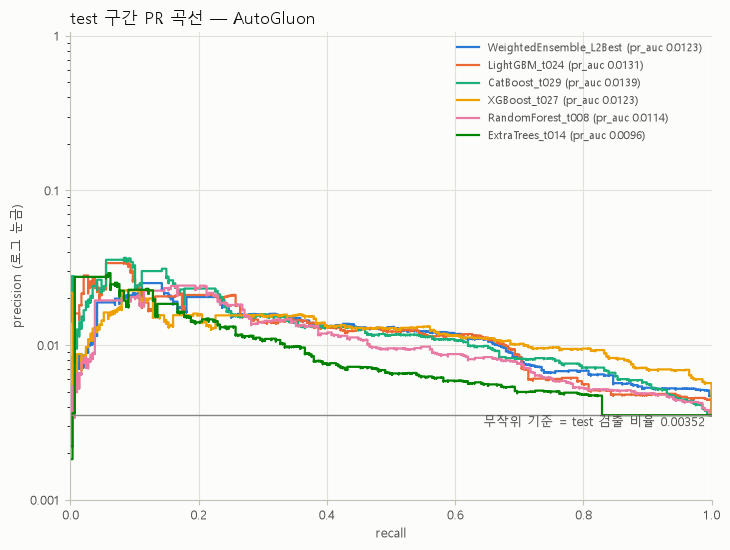

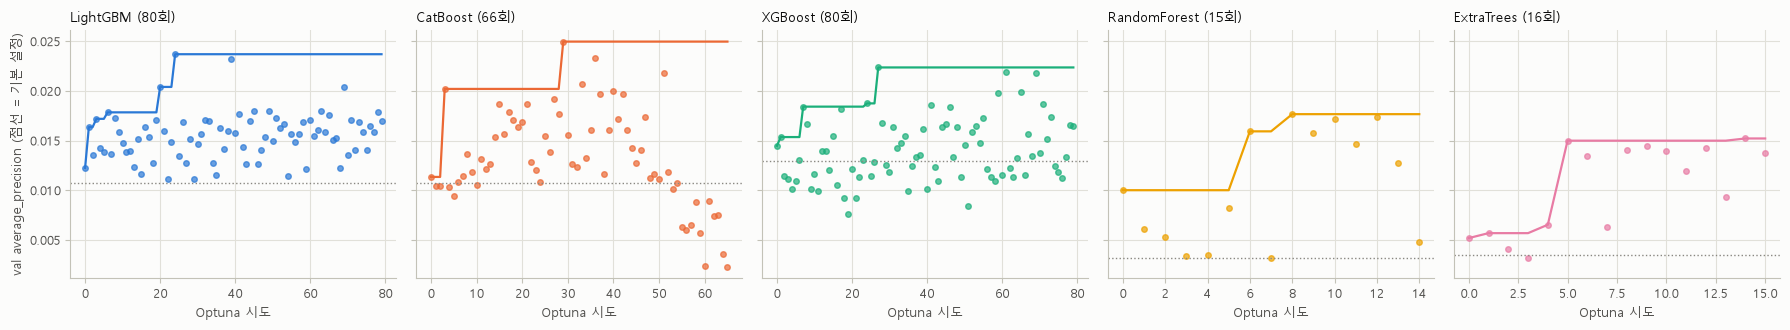

In [9]:
SURFACE, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
PLAIN = FuncFormatter(lambda v, _: f'{v:g}')
FIGURES = {}

def style_axes(ax):
    ax.set_facecolor(SURFACE); ax.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    for side in ('top', 'right'): ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'): ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=AXIS, labelcolor=INK2, labelsize=9)

show_models = [m for m in MODELS if 'WeightedEnsemble' in m] + list(BEST_A.values())
show_models = list(dict.fromkeys(show_models))[:8]
fig, ax = plt.subplots(figsize=(7.4, 5.6), facecolor=SURFACE)
style_axes(ax); ax.set_yscale('log', nonpositive='mask')
for color, m in zip(PALETTE, show_models):
    pr, rc, _ = precision_recall_curve(ys['test'], proba['test'][m])
    ax.plot(rc, pr, drawstyle='steps-post', color=color, linewidth=1.6, label=f'{m} (pr_auc {average_precision_score(ys["test"], proba["test"][m]):.4f})')
pos_rate = ys['test'].mean()
ax.axhline(pos_rate, color=MUTED, linewidth=1)
ax.text(0.99, pos_rate, f'무작위 기준 = test 검출 비율 {pos_rate:.5f}', transform=ax.get_yaxis_transform(), ha='right', va='top', color=INK2, fontsize=9)
ax.set_xlim(0, 1); ax.set_ylim(1e-3, 1.05); ax.yaxis.set_major_formatter(PLAIN)
ax.set_xlabel('recall', color=INK2, fontsize=9); ax.set_ylabel('precision (로그 눈금)', color=INK2, fontsize=9)
ax.set_title('test 구간 PR 곡선 — AutoGluon', loc='left', color=INK, fontsize=12)
ax.legend(frameon=False, fontsize=8, labelcolor=INK2, loc='upper right')
fig.tight_layout(); FIGURES['test_pr_curve.png'] = fig; plt.show()

fig, axes = plt.subplots(1, len(FAMILIES), figsize=(3.6 * len(FAMILIES), 3.4), facecolor=SURFACE, sharey=True)
for ax, fam, color in zip(axes, FAMILIES, PALETTE):
    style_axes(ax)
    d = TRIALS_A[(TRIALS_A['family'] == fam) & (TRIALS_A['state'] == 'OK')].sort_values('trial') if len(TRIALS_A) else pd.DataFrame()
    if len(d):
        ax.plot(d['trial'], d['val_ap'], 'o', color=color, markersize=4, alpha=0.7)
        ax.plot(d['trial'], d['val_ap'].cummax(), color=color, linewidth=1.6)
    base = FAMILY[fam] + '_default'
    if base in lb0.index:
        ax.axhline(lb0.loc[base, 'score_val'], color=MUTED, linestyle=':', linewidth=1)
    ax.set_title(f'{FAMILY[fam]} ({len(d)}회)', loc='left', color=INK, fontsize=10); ax.set_xlabel('Optuna 시도', color=INK2, fontsize=9)
axes[0].set_ylabel('val average_precision (점선 = 기본 설정)', color=INK2, fontsize=9)
fig.tight_layout(); FIGURES['optuna_progress.png'] = fig; plt.show()

These features in provided data are not utilized by the predictor and will be ignored: ['avg_temp_opt_7', 'avg_temp_opt_14', 'avg_temp_opt_30', 'avg_temp_opt_100', 'max_temp_nmiss100', 'min_temp_nmiss100', 'rain_min100', 'max_wind_nmiss100', 'sunshine_nmiss100', 'solar_rad_nmiss100', 'soil_t5_nmiss100', 'soil_t10_nmiss100', 'soil_t20_nmiss100', 'soil_t30_nmiss100', 'soil_moist_nmiss100', 'no2_nmiss100', 'co_nmiss100', 'so2_nmiss100']


순열 중요도 (CatBoost_t029, val 표본) 18초


,중요도 합
group,
기상: rain,0.03342
기상: soil_t30,0.02731
기상: no2,0.02525
기상: soil_moist,0.02360
기상: soil_t10,0.02304
기상: soil_t5,0.02251
기상: min_temp,0.02122
기상: soil_t20,0.02097
기상: co,0.02061


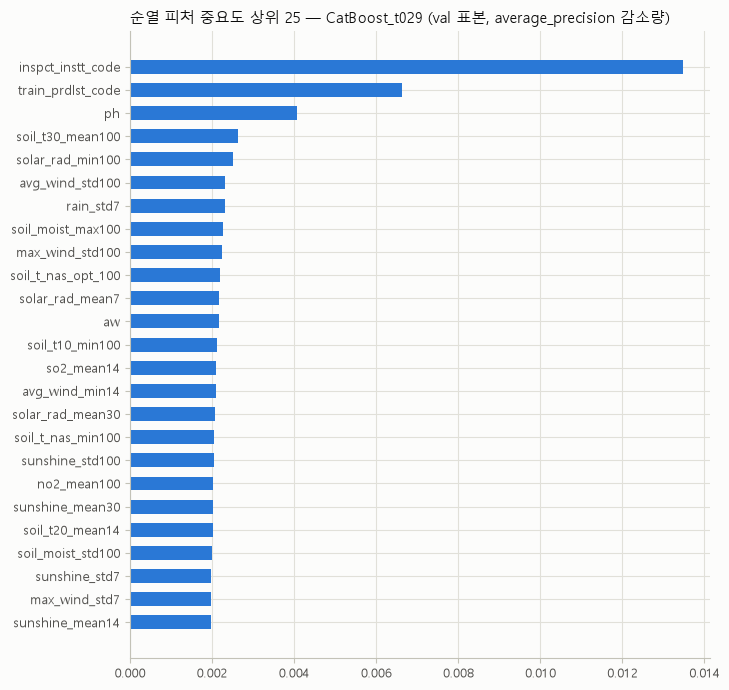

In [10]:
TOP_A = LB_A[~LB_A['model'].str.startswith('WeightedEnsemble')].sort_values('score_val', ascending=False)['model'].iloc[0]
t0 = time.time()
FI = pred_A.feature_importance(frames['val'], model=TOP_A, subsample_size=min(5000, len(frames['val'])), num_shuffle_sets=2,
                               time_limit=900 if not SMOKE_TEST else 120, silent=True)
FI = FI.rename_axis('feature').reset_index()
print(f'순열 중요도 ({TOP_A}, val 표본) {time.time() - t0:.0f}초')

def group_of(f):
    if f in CAT_COLS: return '범주형: ' + f
    if f in META['food_cols']: return '식품: ' + f
    v = f
    for w in ['_mean', '_max', '_min', '_std', '_sum', '_wet', '_maxdry', '_ge30_', '_opt_', '_gem2_', '_lim_', '_nmiss']:
        if w in f: v = f.split(w)[0]; break
    return '기상: ' + v
FI['group'] = FI['feature'].map(group_of)
FI_GROUP = FI.groupby('group')['importance'].sum().sort_values(ascending=False)
display(FI_GROUP.head(20).round(5).to_frame('중요도 합'))

top = FI.sort_values('importance', ascending=False).head(25)[::-1]
fig, ax = plt.subplots(figsize=(7.4, 7.0), facecolor=SURFACE); style_axes(ax)
ax.barh(top['feature'], top['importance'], color=PALETTE[0], height=0.6)
ax.set_title(f'순열 피처 중요도 상위 25 — {TOP_A} (val 표본, average_precision 감소량)', loc='left', color=INK, fontsize=11)
fig.tight_layout(); FIGURES['feature_importance.png'] = fig; plt.show()

## 8. MLflow 에 기록 — 실험 `리스테리아_EXP2`

| 기록 단위 | run 이름 | 내용 |
|---|---|---|
| 부모 run | `2_autogluon` | 조건(입력 파일·분할·피처 수·탐색 예산·시도 수), 산출물(Optuna 시도 표, 리더보드, 최적 설정, 피처 중요도, 그림, 지표 전체 표, 시료별 예측 확률, 모델 저장 경로) |
| 자식 run | `2_autogluon / LightGBM_t017 / F2최대` 처럼 `노트북 / 모델 / 규칙` | `input`, 모델, 임계값, 하이퍼파라미터(`hp.`), 실험 1과 같은 이름의 지표(`val_`·`test_` + accuracy … `n_pred_pos`, `threshold`, `fit_seconds`) |

In [11]:
INPUT = f'다운사이징 + 창집계 {len(FEATURES)}피처 (범주형 {len(CAT_COLS)}·식품 3·기상 집계 {len(FEATURES) - len(CAT_COLS) - 3})'
NOTEBOOK = r'리스테리아ML\EXP\2\2_autogluon.ipynb'
STAGE_DESC = '실험 2 — AutoGluon: 5가족 Optuna 탐색 + 가중 앙상블 (배깅·스태킹 없음)'
METRIC_KEYS = {c_: c_ for c_ in SCORE_COLS + ['TP', 'FN', 'FP', 'TN']}
METRIC_KEYS.update({'전체 건수': 'n_total', '실제 검출': 'n_pos', '예측 양성 수': 'n_pred_pos'})
BOM = chr(0xFEFF)

def hp_of(m):
    try:
        return {k: v for k, v in pred_A.model_hyperparameters(model=m, include_ag_args_ensemble=False, output_format='user').items() if not k.startswith('ag_args')}
    except Exception as e:
        return {'(조회 실패)': str(e)[:80]}

n_trials = {fam: int((TRIALS_A['family'] == fam).sum()) for fam in FAMILIES} if len(TRIALS_A) else {}
parent_params = {
    'input': INPUT, 'data.tabular': str(DATA_DIR / 'tabular.parquet'),
    'data.tabular_mtime': datetime.fromtimestamp((DATA_DIR / 'tabular.parquet').stat().st_mtime).isoformat(timespec='seconds'),
    'data.meta_made_at': META['made_at'], 'n_features': len(FEATURES), 'downsizing': META['downsizing']['rule'],
    **{f'split.{r["구간"]}': f'{r["시작일"]}~{r["종료일"]} | {r["행 수"]:,}행 | 검출 {r["검출(1)"]:,}건' for r in split_summary.to_dict('records')},
    'eval_metric': 'average_precision', 'imbalance': '없음 (재표집·가중 없음; RF·XT class_weight 만 탐색 선택지)', 'threshold_rules': '0.5 / val F1최대 / val F2최대',
    'search': 'Optuna TPE (n_startup 8) → AutoGluon fit_extra 모델 1개씩', 'budget_h': json.dumps(BUDGET_H), 'n_trials': json.dumps(n_trials),
    'max_trials': MAX_TRIALS, 'trial_time_limit_min': TRIAL_TIME_LIMIT_MIN, 'optuna_storage': OPTUNA_STORAGE,
    'bagging_stacking': '없음 (사용자 결정 2026-09-29 — OOF 분할이 시간 순서를 어겨서)',
    'mem_limit_gb': MEM_LIMIT_GB, 'mem_ratio': json.dumps(MEM_RATIO),
    'device': f'CatBoost GPU · XGBoost {"GPU" if XGB_GPU else "CPU"} · LightGBM·RF·XT CPU', 'seed': SEED, 'ag_path': str(AG_OUT), 'smoke_test': SMOKE_TEST,
}
pred_out = pd.concat([pd.DataFrame({KEY_COL: tab.loc[rows[s], KEY_COL].to_numpy(), '구간': s, DATE_COL: tab.loc[rows[s], DATE_COL].to_numpy(),
                                    'y': ys[s], **{f'p_{m}': proba[s][m] for m in MODELS}}) for s in ['val', 'test']], ignore_index=True)

if LOG_TO_MLFLOW:
    with mlflow.start_run(run_name=RUN_NAME) as parent:
        mlflow.set_tags({'notebook': NOTEBOOK, 'stage': STAGE_DESC, 'mlflow.note.content': STAGE_DESC})
        mlflow.log_params(parent_params)
        for fname, fig in FIGURES.items():
            mlflow.log_figure(fig, f'figures/{fname}')
        mlflow.log_text(BOM + TRIALS_A.to_csv(index=False), 'optuna_trials_A.csv')
        mlflow.log_text(BOM + LB_A.to_csv(index=False), 'leaderboard.csv')
        mlflow.log_text(BOM + FI.to_csv(index=False), 'feature_importance.csv')
        mlflow.log_text(BOM + metrics.to_csv(index=False), 'metrics.csv')
        mlflow.log_dict({'best_A': BEST_A, 'best_params': BEST_PARAMS, 'round0': ROUND0, 'thresholds': thresholds,
                         'fit_seconds': FIT_SECONDS_A,
                         'versions': {'autogluon': agt.__version__, 'optuna': optuna.__version__, 'xgboost': xgboost.__version__, 'sklearn': sklearn.__version__, 'python': sys.version.split()[0]}},
                        'config.json')
        with tempfile.TemporaryDirectory() as tmp:
            p = Path(tmp) / 'predictions.parquet'; pred_out.to_parquet(p, index=False); mlflow.log_artifact(str(p))
        for m in MODELS:
            hp = {f'hp.{k}': v for k, v in hp_of(m).items()}
            for rule, t in thresholds[m].items():
                with mlflow.start_run(run_name=f'{RUN_NAME} / {m} / {rule}', nested=True):
                    mlflow.set_tags({'notebook': NOTEBOOK, 'stage': STAGE_DESC, 'model': m, 'threshold_rule': rule})
                    mlflow.log_params({'input': INPUT, 'model': m, 'threshold_rule': rule, 'threshold': t, **hp})
                    values = {'threshold': t, 'fit_seconds': FIT_TIME[m]}
                    for s in ['val', 'test']:
                        row = metrics[(metrics['모델'] == m) & (metrics['구간'] == s) & (metrics['임계값 규칙'] == rule)].iloc[0]
                        values.update({f'{s}_{key}': float(row[col]) for col, key in METRIC_KEYS.items()})
                    mlflow.log_metrics(values)
    PARENT_RUN_ID = parent.info.run_id
    print('기록 완료 — 부모 run', RUN_NAME, PARENT_RUN_ID, '| 자식', len(MODELS) * 3)
else:
    PARENT_RUN_ID = None
    print('LOG_TO_MLFLOW = False — 기록하지 않음')

기록 완료 — 부모 run 2_autogluon 50c219ef031749938aedff3ca51cff05 | 자식 18


## 9. 실험 1 과 비교 (test, F2최대 임계값, pr_auc 순)

실험 1(`리스테리아_EXP1`)의 `2_바로학습`(LIMS 10칼럼 기본값)·`3_기상조인_후_학습`(하루값 1,700칼럼)·베이스라인과 이번 결과를 나란히 놓는다. (점검 실행에서는 표본의 검출 비율이 달라 실험 1 수치와 비교할 수 없다.)

In [12]:
def exp1_rows():
    r = mlflow.search_runs(experiment_names=['리스테리아_EXP1'], filter_string="params.threshold_rule = 'F2최대'")
    if r.empty or 'tags.mlflow.parentRunId' not in r: return pd.DataFrame()
    r = r[r['tags.mlflow.parentRunId'].notna()]
    return pd.DataFrame({'모델': r['tags.mlflow.runName'], 'roc_auc': r['metrics.test_roc_auc'], 'pr_auc': r['metrics.test_pr_auc'],
                         'recall': r['metrics.test_recall'], 'precision': r['metrics.test_precision'], 'TP': r['metrics.test_TP'],
                         '예측 양성 수': r['metrics.test_n_pred_pos']})
e2 = metrics[(metrics['구간'] == 'test') & (metrics['임계값 규칙'] == 'F2최대')][['모델', 'roc_auc', 'pr_auc', 'recall', 'precision', 'TP', '예측 양성 수']]
cmp = pd.concat([exp1_rows(), e2.assign(모델='2_autogluon / ' + e2['모델'])], ignore_index=True).sort_values('pr_auc', ascending=False).reset_index(drop=True)
display(cmp.round(4).head(30))

,모델,roc_auc,pr_auc,recall,precision,TP,예측 양성 수
0,2_바로학습 / CatBoost / F2최대,0.7975,0.0190,0.2160,0.0284,62.0,2186.0
1,2_바로학습 / LightGBM / F2최대,0.7838,0.0166,0.0348,0.0633,10.0,158.0
2,CatBoost / F2최대,0.7834,0.0165,0.2962,0.0233,85.0,3652.0
3,2_autogluon / CatBoost_t029,0.7743,0.0139,0.0871,0.0351,25.0,712.0
4,2_autogluon / LightGBM_t024,0.7568,0.0131,0.0941,0.0317,27.0,852.0
5,2_바로학습 / XGBoost / F2최대,0.7856,0.0130,0.0348,0.0173,10.0,579.0
6,2_autogluon / XGBoost_t027,0.8174,0.0123,0.1289,0.0193,37.0,1915.0
7,2_autogluon / WeightedEnsemble_L2Best,0.7794,0.0123,0.2474,0.0174,71.0,4069.0
8,LightGBM / F2최대,0.7579,0.0122,0.2369,0.0185,68.0,3681.0
9,2_autogluon / RandomForest_t008,0.7392,0.0114,0.0348,0.0082,10.0,1216.0
